444 body-point files found


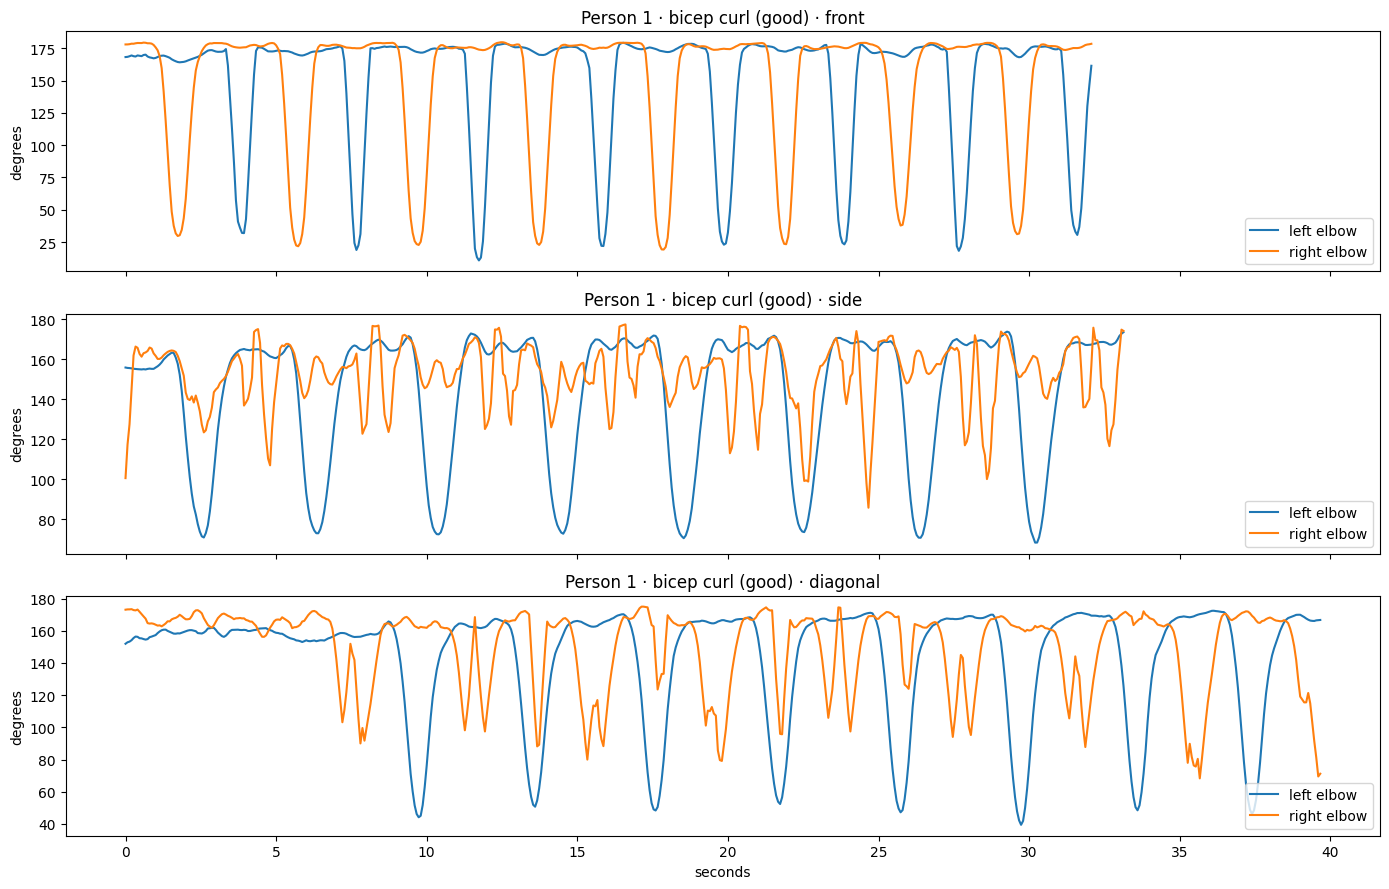

In [1]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

DATA_DIR = kagglehub.dataset_download('studiousdost0on/gym-rep-counter-data')
landmark_files = glob.glob(f'{DATA_DIR}/**/*.parquet', recursive=True)
if not landmark_files:
    zip_file = glob.glob(f'{DATA_DIR}/**/landmarks_phase1.zip', recursive=True)[0]
    with zipfile.ZipFile(zip_file) as archive:
        archive.extractall('/kaggle/working/landmarks')
    landmark_files = glob.glob('/kaggle/working/landmarks/**/*.parquet', recursive=True)
print(f'{len(landmark_files)} body-point files found')

landmark_paths = {os.path.basename(path).replace('.parquet', ''): path for path in landmark_files}

def load_video(subject, exercise, quality, view):
    name = f'subject_{subject:03d}_{exercise}_{quality}_{view}'
    if name not in landmark_paths and exercise == 'bicep_curl':
        name = name.replace('bicep_curl', 'bicep')
    return pd.read_parquet(landmark_paths[name]) if name in landmark_paths else None

def elbow_angle(landmarks, shoulder, elbow, wrist):
    width, height = landmarks['width'].iloc[0], landmarks['height'].iloc[0]
    def x(point): return landmarks[f'{point}_x'] * width
    def y(point): return landmarks[f'{point}_y'] * height
    upper_arm_x, upper_arm_y = x(shoulder) - x(elbow), y(shoulder) - y(elbow)
    forearm_x, forearm_y = x(wrist) - x(elbow), y(wrist) - y(elbow)
    cosine = (upper_arm_x * forearm_x + upper_arm_y * forearm_y) / (
        np.hypot(upper_arm_x, upper_arm_y) * np.hypot(forearm_x, forearm_y) + 1e-8)
    return np.degrees(np.arccos(np.clip(cosine, -1, 1)))

subject = 1
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for axis, view in zip(axes, ['front', 'side', 'diagonal']):
    landmarks = load_video(subject, 'bicep_curl', 'good', view)
    if landmarks is None:
        axis.set_title(f'{view}: not found')
        continue
    fps = landmarks['fps'].iloc[0]
    seconds = np.arange(len(landmarks)) / fps
    left = pd.Series(elbow_angle(landmarks, 11, 13, 15)).rolling(5, center=True, min_periods=1).mean()
    right = pd.Series(elbow_angle(landmarks, 12, 14, 16)).rolling(5, center=True, min_periods=1).mean()
    axis.plot(seconds, left, label='left elbow')
    axis.plot(seconds, right, label='right elbow')
    axis.set_title(f'Person {subject} · bicep curl (good) · {view}')
    axis.set_ylabel('degrees')
    axis.legend(loc='lower right')
axes[-1].set_xlabel('seconds')
plt.tight_layout()
plt.show()


### 3.2 - Curl counter (per arm, front view)
**Why:** Count alternating curls separately for each arm ("Left: 8 · Right: 8").

**How:** Elbow angle per arm → find each deep dip (≥ 60° drop, ≥ 0.8 s apart), same peak trick as the squat counter.

**Free accuracy check:** In alternating curls, left and right should be EQUAL (± 1). Big differences = a counting error.

**Input:** All Mendeley FRONT curl videos (good + bad, ~50)

**If something breaks:** An arm shows "hidden" when its elbow/wrist visibility is < 0.5, which is expected for a hidden arm.

In [4]:
from scipy.signal import find_peaks

MIN_ARM_VISIBILITY = 0.5

def count_arm_reps(landmarks, shoulder, elbow, wrist, min_drop_degrees=60, min_gap_seconds=0.8):
    arm_visibility = landmarks[[f'{elbow}_vis', f'{wrist}_vis']].min(axis=1).mean()
    if arm_visibility < MIN_ARM_VISIBILITY:
        return None, arm_visibility
    # If the model can't see this arm's elbow and wrist well enough, don't guess: return None ("hidden").

    fps = landmarks['fps'].iloc[0]
    angle = pd.Series(elbow_angle(landmarks, shoulder, elbow, wrist)).interpolate(limit_direction='both')
    angle = angle.rolling(5, center=True, min_periods=1).mean().to_numpy()
    curl_signal = 180 - angle

    peaks, _ = find_peaks(curl_signal, prominence=min_drop_degrees, distance=max(int(fps * min_gap_seconds), 1))
    return len(peaks), arm_visibility

results = []
for subject in range(1, 27):
    for quality in ['good', 'bad']:
        landmarks = load_video(subject, 'bicep_curl', quality, 'front')
        if landmarks is None:
            continue
        left_count, left_visibility = count_arm_reps(landmarks, 11, 13, 15)
        right_count, right_visibility = count_arm_reps(landmarks, 12, 14, 16)
        results.append({'subject': subject, 'quality': quality,
                        'left': left_count, 'right': right_count,
                        'left_vis': round(left_visibility, 2), 'right_vis': round(right_visibility, 2)})
results = pd.DataFrame(results)

both_arms = results.dropna(subset=['left', 'right'])
difference = (both_arms['left'] - both_arms['right']).abs()
print(f'{len(results)} front curl videos | both arms visible in {len(both_arms)}')
print(f'Left = Right exactly:  {(difference == 0).mean():.0%}')
print(f'Within 1 rep:          {(difference <= 1).mean():.0%}')
print('\nVideos where left and right differ by 2+ (likely counting errors):')
print(both_arms[difference >= 2].to_string(index=False))


50 front curl videos | both arms visible in 50
Left = Right exactly:  50%
Within 1 rep:          92%

Videos where left and right differ by 2+ (likely counting errors):
 subject quality  left  right  left_vis  right_vis
       2     bad     3      6      0.93       0.93
       7     bad     5     17      0.94       0.95
      17     bad    10      5      0.99       0.97
      20     bad     4      8      0.97       0.96


### 3.3 – Look at the 4 curl videos where left ≠ right
**Why:** All 4 counting errors are "bad" videos. Are they partial curls (fixable), noise, or broken data?
**What:** Plots left + right elbow angles for persons 2, 7, 17 and 20 (bad, front) with the counted peaks marked.
**Look for:** dips that don't reach the dashed 60°-drop line = partial curls the counter skipped

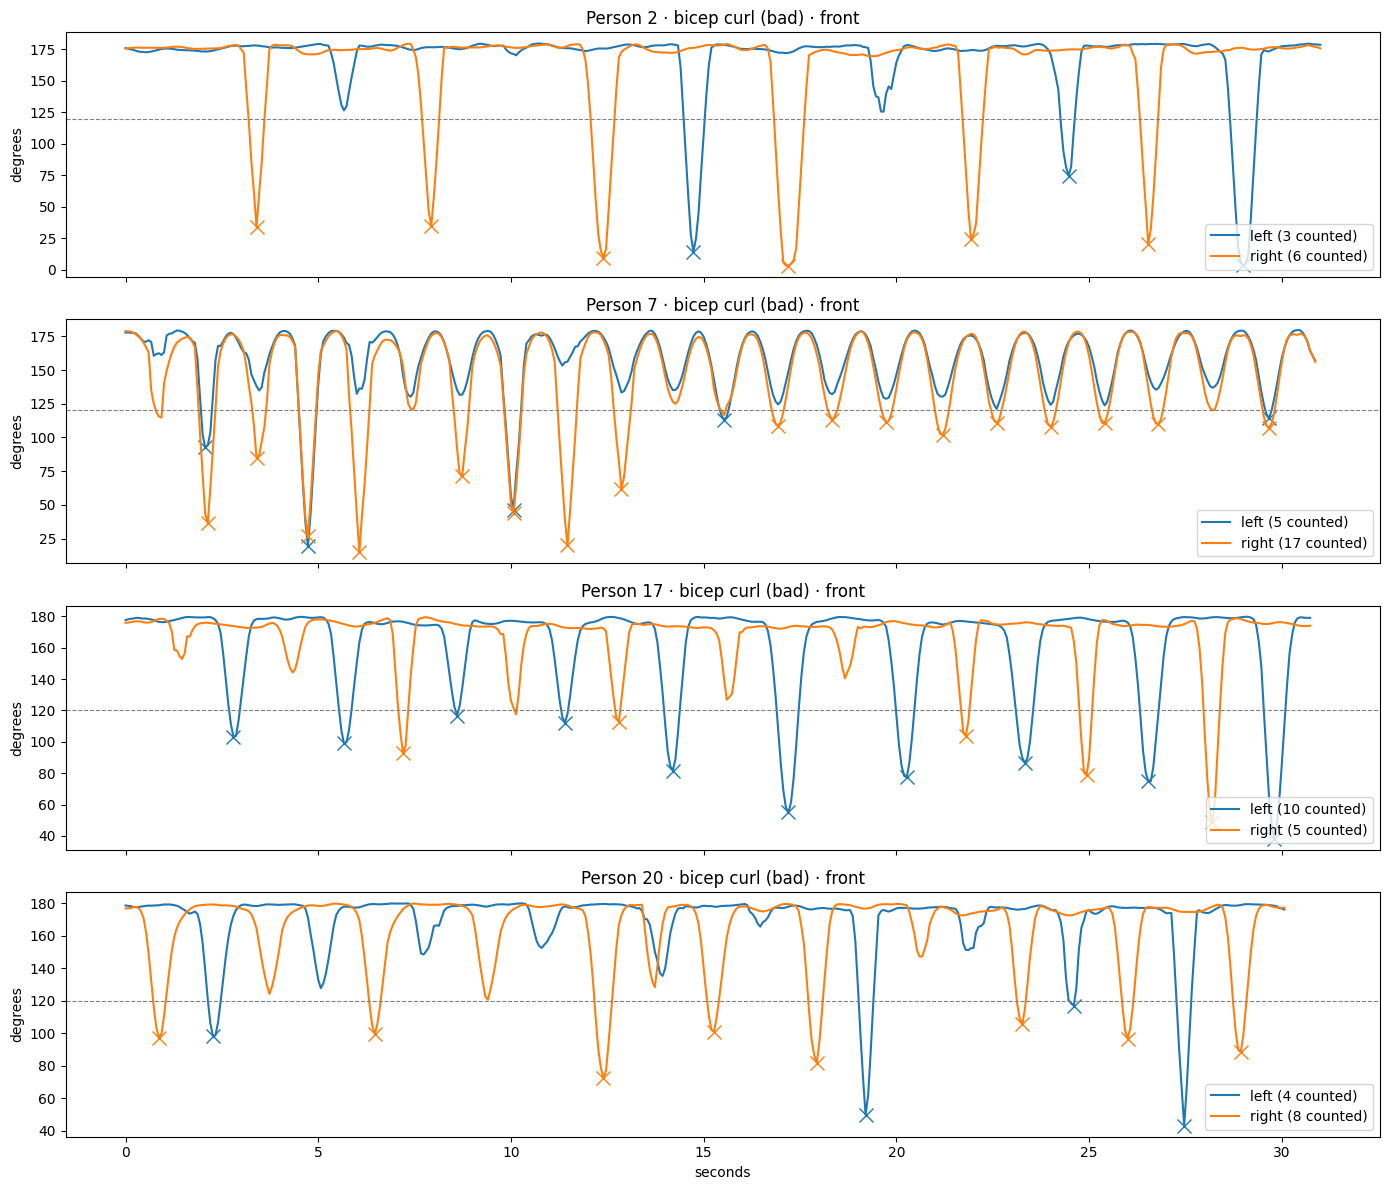

In [5]:
problem_subjects = [2, 7, 17, 20]
fig, axes = plt.subplots(len(problem_subjects), 1, figsize=(14, 12), sharex=True)
for axis, subject in zip(axes, problem_subjects):
    landmarks = load_video(subject, 'bicep_curl', 'bad', 'front')
    fps = landmarks['fps'].iloc[0]
    seconds = np.arange(len(landmarks)) / fps
    for shoulder, elbow, wrist, name, color in [(11, 13, 15, 'left', 'tab:blue'), (12, 14, 16, 'right', 'tab:orange')]:
        angle = pd.Series(elbow_angle(landmarks, shoulder, elbow, wrist)).interpolate(limit_direction='both')
        angle = angle.rolling(5, center=True, min_periods=1).mean().to_numpy()
        peaks, _ = find_peaks(180 - angle, prominence=60, distance=int(fps * 0.8))
        axis.plot(seconds, angle, color=color, label=f'{name} ({len(peaks)} counted)')
        axis.plot(seconds[peaks], angle[peaks], 'x', color=color, markersize=10)
    # For each arm: the smoothed elbow angle line + an ✕ on every curl the counter counted.
    # A dip WITHOUT an ✕ = a curl the counter skipped.

    axis.axhline(180 - 60, color='gray', linestyle='--', linewidth=0.8)
    axis.set_title(f'Person {subject} · bicep curl (bad) · front')
    axis.set_ylabel('degrees')
    axis.legend(loc='lower right')
    # Dashed line at 120° = roughly where a dip needs to reach to count (a 60° drop from a straight arm).
axes[-1].set_xlabel('seconds')
plt.tight_layout()
plt.show()

### 3.4 – Curl counter v2: count every curl, then grade it
**Why:** All 4 errors in 3.2 were PARTIAL curls (only 25–55° of bend) that the 60° threshold skipped.

**What:** Counts any curl with ≥ 25° of bend, then grades each one: smallest elbow angle ≤ 70° = ✅ full, > 70° = ⚠️ partial.

**Output:** Per arm: total curls + how many were partial. Re-runs the left = right check on all 50 front videos.

**If something breaks:** If "Within 1 rep" gets WORSE, 25° is too low and counts noise, so try 35°.

In [6]:
FULL_CURL_MAX_ANGLE = 70


def count_arm_reps(landmarks, shoulder, elbow, wrist, min_drop_degrees=25, min_gap_seconds=0.8):
    arm_visibility = landmarks[[f'{elbow}_vis', f'{wrist}_vis']].min(axis=1).mean()
    if arm_visibility < MIN_ARM_VISIBILITY:
        return None, None, arm_visibility
    # Unchanged: a hidden arm returns None.

    fps = landmarks['fps'].iloc[0]
    angle = pd.Series(elbow_angle(landmarks, shoulder, elbow, wrist)).interpolate(limit_direction='both')
    angle = angle.rolling(5, center=True, min_periods=1).mean().to_numpy()
    peaks, _ = find_peaks(180 - angle, prominence=min_drop_degrees, distance=max(int(fps * min_gap_seconds), 1))

    top_angles = angle[peaks]
    partial_count = int((top_angles > FULL_CURL_MAX_ANGLE).sum())
    return len(peaks), partial_count, arm_visibility

results = []
for subject in range(1, 27):
    for quality in ['good', 'bad']:
        landmarks = load_video(subject, 'bicep_curl', quality, 'front')
        if landmarks is None:
            continue
        left_count, left_partial, _ = count_arm_reps(landmarks, 11, 13, 15)
        right_count, right_partial, _ = count_arm_reps(landmarks, 12, 14, 16)
        results.append({'subject': subject, 'quality': quality,
                        'left': left_count, 'left_partial': left_partial,
                        'right': right_count, 'right_partial': right_partial})
results = pd.DataFrame(results)

difference = (results['left'] - results['right']).abs()
print(f'Left = Right exactly:  {(difference == 0).mean():.0%}   (was 50%)')
print(f'Within 1 rep:          {(difference <= 1).mean():.0%}   (was 92%)')
print('\nStill differing by 2+:')
print(results[difference >= 2].to_string(index=False))

results['partial_share'] = (results['left_partial'] + results['right_partial']) / (results['left'] + results['right'])
print('\nShare of partial curls:')
print(results.groupby('quality')['partial_share'].mean().map('{:.0%}'.format).to_string())
# Bonus: what % of curls were partial, in GOOD vs BAD videos.
# If "bad" videos have many more partial curls, the rule matches the dataset's labels.

Left = Right exactly:  50%   (was 50%)
Within 1 rep:          94%   (was 92%)

Still differing by 2+:
 subject quality  left  left_partial  right  right_partial
       7     bad    20            18     22             16
      20     bad     9             7     12             12
      26     bad     5             2      8              7

Share of partial curls:
quality
bad     21%
good     1%


### 3.5 – Front-view detector (body turn angle)
**Why:** Curls are only counted from the front, so the app must detect "not front" → "Face the camera". The old shoulder-width check failed (side 0.67 vs front 0.71).

**What:** Body turn angle from the shoulders: atan(|z difference| / |x difference|). 0° = facing the camera, 90° = side.

**Test:** Compute it for all 444 Mendeley videos and compare with their REAL view labels (front/side/diagonal), then find the best cutoff for "front".

**If something breaks:** z is in roughly the same units as x (both relative to the image width), which is why we use raw x and z, not pixels.

In [7]:
def body_turn_angle(landmarks):
    shoulders_visible = landmarks[['11_vis', '12_vis']].min(axis=1) > 0.5
    x_difference = (landmarks['11_x'] - landmarks['12_x']).abs()
    z_difference = (landmarks['11_z'] - landmarks['12_z']).abs()
    turn_per_frame = np.degrees(np.arctan2(z_difference, x_difference))
    return float(turn_per_frame[shoulders_visible].median()) if shoulders_visible.any() else np.nan

video_angles = []
for name, path in landmark_paths.items():
    parts = name.split('_')
    exercise = 'bicep_curl' if parts[2] == 'bicep' else '_'.join(parts[2:-2])
    video_angles.append({'exercise': exercise, 'view': parts[-1],
                         'turn_angle': body_turn_angle(pd.read_parquet(path))})
video_angles = pd.DataFrame(video_angles)

print('Median body turn angle (degrees) by real camera view:')
print(video_angles.pivot_table(index='exercise', columns='view', values='turn_angle', aggfunc='median').round(0))

is_front = video_angles['view'] == 'front'
best_cutoff, best_accuracy = max(
    ((cutoff, ((video_angles['turn_angle'] < cutoff) == is_front).mean()) for cutoff in range(5, 60)),
    key=lambda pair: pair[1])
print(f'\nBest cutoff: turn angle < {best_cutoff}° = "front" → {best_accuracy:.0%} of videos classified correctly')
for exercise, group in video_angles.groupby('exercise'):
    accuracy = ((group['turn_angle'] < best_cutoff) == (group['view'] == 'front')).mean()
    print(f'   {exercise:<11} {accuracy:.0%}')

plt.figure(figsize=(10, 4))
for view, color in [('front', 'tab:green'), ('diagonal', 'tab:orange'), ('side', 'tab:red')]:
    plt.hist(video_angles.loc[video_angles['view'] == view, 'turn_angle'], bins=30, range=(0, 90),
             alpha=0.5, color=color, label=view)
plt.axvline(best_cutoff, color='black', linestyle='--', label=f'cutoff {best_cutoff}°')
plt.xlabel('body turn angle (degrees)')
plt.ylabel('number of videos')
plt.legend()
plt.show()


KeyboardInterrupt: 

### 3.6 – Setup for the Kaggle reality check (barbell curls)
**Why:** Mendeley is clean and controlled. Does the curl counter + front detector also work on messy real-world gym videos?

**What:** Installs MediaPipe, downloads the pose model, re-creates `extract_landmarks` + `quiet` (from notebook 01), attaches the Kaggle workout dataset and picks 10 random barbell curl videos.

**Output:** The list of 10 videos with their length

**If something breaks:** Internet must be ON. The pip "dependency conflict" message is harmless (same as notebook 01).

In [ ]:
!pip install -q mediapipe
!wget -q -O /kaggle/working/pose_landmarker_full.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task
# The pose model setup from notebook 01 (installed here because each notebook has its own machine).

import sys, random, subprocess
from contextlib import contextmanager
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from IPython.display import Video

MODEL_PATH = '/kaggle/working/pose_landmarker_full.task'
COLUMNS = ['frame'] + [f'{point}_{value}' for point in range(33) for value in ('x', 'y', 'z', 'vis')]

@contextmanager
def quiet():
    sys.stdout.flush()
    sys.stderr.flush()
    devnull = os.open(os.devnull, os.O_WRONLY)
    saved = os.dup(2)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)

def extract_landmarks(video_path):
    options = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.VIDEO, num_poses=1)
    landmarker = vision.PoseLandmarker.create_from_options(options)
    capture = cv2.VideoCapture(video_path)
    fps = capture.get(cv2.CAP_PROP_FPS) or 30
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    rows, frame_index = [], 0
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        result = landmarker.detect_for_video(image, int(frame_index * 1000 / fps))
        if result.pose_landmarks:
            rows.append([frame_index] + [v for p in result.pose_landmarks[0] for v in (p.x, p.y, p.z, p.visibility)])
        else:
            rows.append([frame_index] + [np.nan] * 132)
        frame_index += 1
    capture.release()
    landmarker.close()
    landmarks = pd.DataFrame(rows, columns=COLUMNS)
    landmarks['fps'], landmarks['width'], landmarks['height'] = fps, width, height
    return landmarks

WORKOUT_DIR = kagglehub.dataset_download('hasyimabdillah/workoutfitness-video')
curl_videos = sorted(glob.glob(f'{WORKOUT_DIR}/**/hammer curl/*', recursive=True))
random.seed(42)
curl_batch = random.sample(curl_videos, 10)

print(f'{len(curl_videos)} hammer curl videos available → testing 10:')
for number, video_path in enumerate(curl_batch):
    capture = cv2.VideoCapture(video_path)
    seconds = capture.get(cv2.CAP_PROP_FRAME_COUNT) / (capture.get(cv2.CAP_PROP_FPS) or 30)
    capture.release()
    print(f'  [{number}] {os.path.basename(video_path):<32} {seconds:5.1f}s')


### 3.7 – Run the curl counter + front detector on 10 Kaggle videos
**What:** For each video: pose → body turn angle → if front (< 40°), count curls per arm (+ partial), otherwise "Face the camera".

**Expected:** Barbell curls move both arms together, so left = right (more strictly than for alternating curls).

**Next:** Watch each video and count by hand to compare.

**If something breaks:** Very short clips may start mid-curl, so a cut-off first or last rep is a known edge case.

In [ ]:
FRONT_VIEW_MAX_ANGLE = 40

kaggle_results = []
for number, video_path in enumerate(curl_batch):
    with quiet():
        landmarks = extract_landmarks(video_path)
    turn_angle = body_turn_angle(landmarks)
    row = {'#': number, 'video': os.path.basename(video_path), 'turn_angle': round(turn_angle)}
    # Runs the pose model (muted) and measures how far the body is turned.

    if np.isnan(turn_angle) or turn_angle >= FRONT_VIEW_MAX_ANGLE:
        row['result'] = '↪️ Face the camera'
    else:
        left_count, left_partial, _ = count_arm_reps(landmarks, 11, 13, 15)
        right_count, right_partial, _ = count_arm_reps(landmarks, 12, 14, 16)
        row['result'] = f'Left: {left_count} ({left_partial} partial) · Right: {right_count} ({right_partial} partial)'
    kaggle_results.append(row)

kaggle_results = pd.DataFrame(kaggle_results)
print(kaggle_results.to_string(index=False))

### 3.8 – Watch the 10 Kaggle curl videos (check counts + camera angle)
**What:** `watch(number)` plays one Kaggle video small and light (same idea as before).

**Note for each video:** (1) real number of curls, (2) real camera angle: front / diagonal / side.

**Questions:** Are the 6 "Face the camera" videos REALLY not front? Is #0 (35°) front-ish or diagonal?

In [ ]:
def watch(number):
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', curl_batch[number],
                    '-vf', 'scale=360:-2,fps=15', '-an', '-vcodec', 'libx264',
                    '-crf', '32', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', 'preview.mp4'])
    row = kaggle_results.loc[number]
    print(f'[{number}] {row["video"]} | turn angle {row["turn_angle"]}° → {row["result"]}')
    return Video('preview.mp4', embed=True, width=360)

watch(0)
# person 0 moving camera
# person 1: totally from the side 
# person 2:  turn angle 11° → Left: 3 (0 partial) · Right: 2 (0 partial) ✅
# person 3: turn angle 64° → ↪️ Face the camera. it was unusual curls and side-ish
# person 4: totally  from the side
# person 5:  turn angle 60° → ↪️ Face the camera. camera was moving to the side
# person 6: totally  from the side
# person 7: totally  from the side
# person 8: turn angle 30° → Left: 3 (1 partial) · Right: 5 (0 partial), both 3 but unusual curls
# person 9: ✅ he was lifting both at the same time but correctly counted



### 3.9 – Count ALL 10 Kaggle videos (ignore the front check)
**Why:** The front detector rejected 5 videos that looked front-ish to me (63–66°). Can we still count correctly at those angles?

**What:** Runs the curl counter on every video regardless of the turn angle, so I can compare with the real counts.

**Decision:** If the counts are right at ~65° → raise the cutoff. If they're wrong → keep 40°.

In [ ]:
all_counts = []
for number, video_path in enumerate(curl_batch):
    with quiet():
        landmarks = extract_landmarks(video_path)
    left_count, left_partial, left_visibility = count_arm_reps(landmarks, 11, 13, 15)
    right_count, right_partial, right_visibility = count_arm_reps(landmarks, 12, 14, 16)
    all_counts.append({
        '#': number,
        'turn_angle': kaggle_results.loc[number, 'turn_angle'],
        'left': left_count, 'left_partial': left_partial, 'left_vis': round(left_visibility, 2),
        'right': right_count, 'right_partial': right_partial, 'right_vis': round(right_visibility, 2),
    })
print(pd.DataFrame(all_counts).to_string(index=False))


### 3.10 – Look at push-up signals (elbow angle vs shoulder height)
**Why:** Before building the push-up counter, SEE which signal is cleanest, like we did for curls.

**What:** For person 1 (good push-ups), 3 camera views: left = both elbow angles, right = shoulder height above the wrists (in arm lengths).

**Look for:** Which signal shows clean, regular waves in which view?

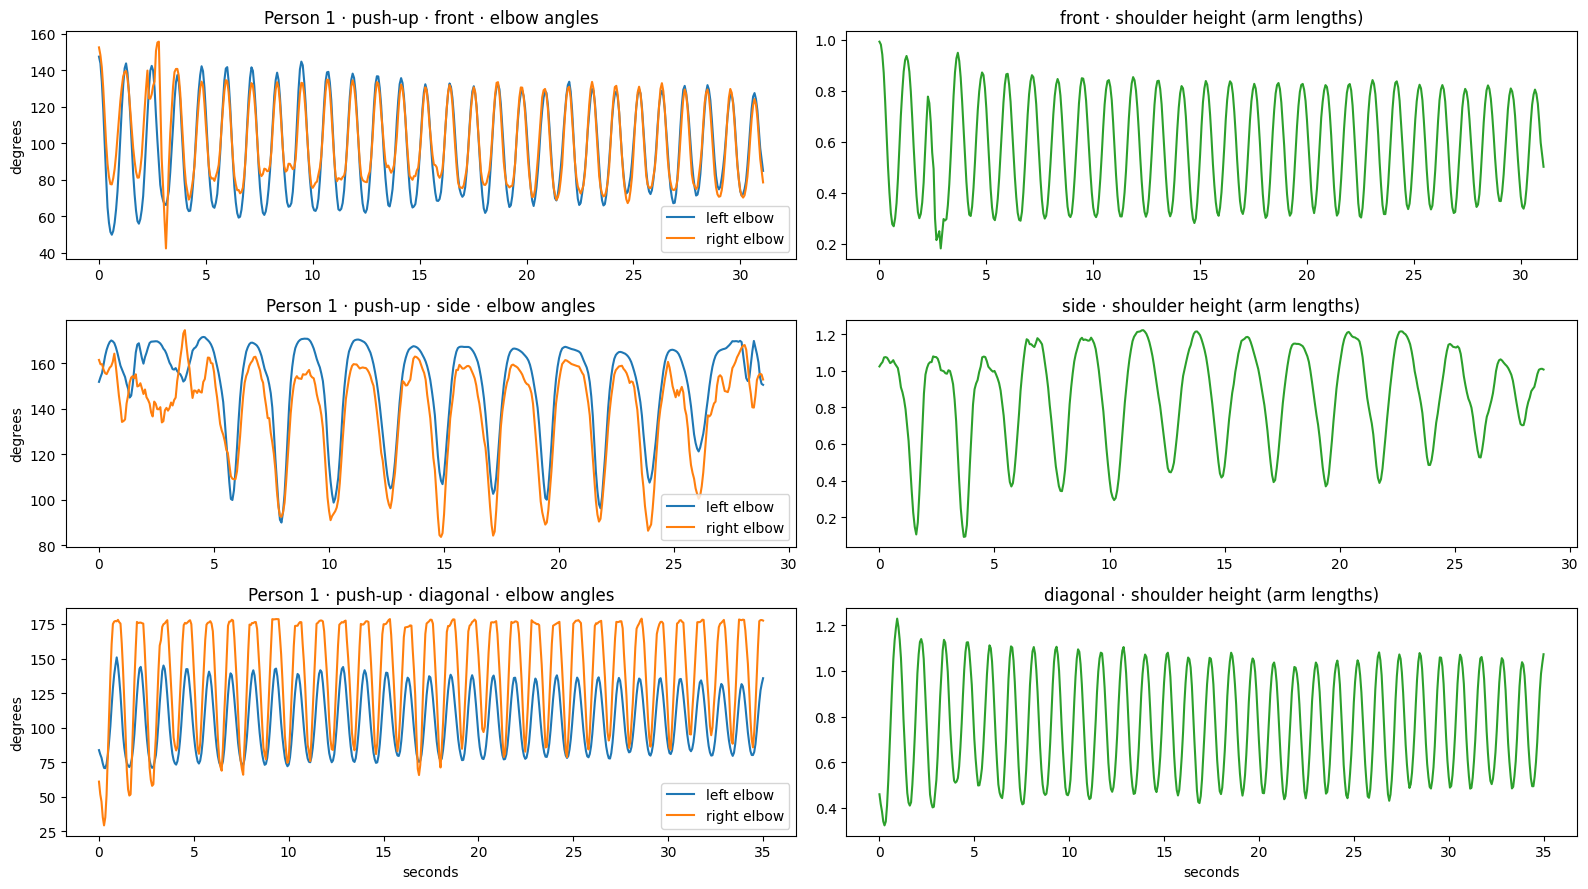

In [8]:
def shoulder_height(landmarks):
    width, height = landmarks['width'].iloc[0], landmarks['height'].iloc[0]
    def x(point): return landmarks[f'{point}_x'] * width
    def y(point): return landmarks[f'{point}_y'] * height
    sides = []
    for shoulder, elbow, wrist in [(11, 13, 15), (12, 14, 16)]:
        arm_length = (np.hypot(x(shoulder) - x(elbow), y(shoulder) - y(elbow))
                      + np.hypot(x(elbow) - x(wrist), y(elbow) - y(wrist)))
        sides.append((y(wrist) - y(shoulder)) / arm_length.rolling(60, center=True, min_periods=1).median())
    return (sides[0] + sides[1]) / 2

subject = 1
fig, axes = plt.subplots(3, 2, figsize=(16, 9), sharex='row')
for row_axes, view in zip(axes, ['front', 'side', 'diagonal']):
    landmarks = load_video(subject, 'push_up', 'good', view)
    if landmarks is None:
        row_axes[0].set_title(f'{view}: not found')
        continue
    seconds = np.arange(len(landmarks)) / landmarks['fps'].iloc[0]
    for shoulder, elbow, wrist, name in [(11, 13, 15, 'left'), (12, 14, 16, 'right')]:
        angle = pd.Series(elbow_angle(landmarks, shoulder, elbow, wrist)).rolling(5, center=True, min_periods=1).mean()
        row_axes[0].plot(seconds, angle, label=f'{name} elbow')
    row_axes[0].set_title(f'Person {subject} · push-up · {view} · elbow angles')
    row_axes[0].set_ylabel('degrees')
    row_axes[0].legend(loc='lower right')
    # Left column: both elbow angles over time (like the curl charts).

    height_signal = shoulder_height(landmarks).rolling(5, center=True, min_periods=1).mean()
    row_axes[1].plot(seconds, height_signal, color='tab:green')
    row_axes[1].set_title(f'{view} · shoulder height (arm lengths)')
    # Right column: the shoulder-height signal.
for axis in axes[-1]:
    axis.set_xlabel('seconds')
plt.tight_layout()
plt.show()

### 3.11 – Push-up counter (shoulder height) + cross-check (elbow angle)
**Why:** Shoulder height looked clean in all 3 views, so push-ups may not need the front-only rule.

**How:** Each dip in shoulder height (≥ 0.2 arm lengths, ≥ 0.5 s apart) = 1 push-up. Independently, count dips in the elbow angle (≥ 25°).

**Side choice:** If one arm is much less visible (side view), use only the better-visible side; otherwise average both.

**Free accuracy check:** Two independent signals → if both counts agree, the count is probably right.

**Input:** All 144 Mendeley push-up videos

In [9]:
def arm_signals(landmarks, shoulder, elbow, wrist):
    width, height = landmarks['width'].iloc[0], landmarks['height'].iloc[0]
    def x(point): return landmarks[f'{point}_x'] * width
    def y(point): return landmarks[f'{point}_y'] * height
    arm_length = (np.hypot(x(shoulder) - x(elbow), y(shoulder) - y(elbow))
                  + np.hypot(x(elbow) - x(wrist), y(elbow) - y(wrist)))
    shoulder_above_wrist = (y(wrist) - y(shoulder)) / arm_length.rolling(60, center=True, min_periods=1).median()
    angle = pd.Series(elbow_angle(landmarks, shoulder, elbow, wrist))
    visibility = landmarks[[f'{shoulder}_vis', f'{elbow}_vis', f'{wrist}_vis']].min(axis=1).mean()
    return shoulder_above_wrist, angle, visibility

def pushup_signals(landmarks):
    left_height, left_angle, left_visibility = arm_signals(landmarks, 11, 13, 15)
    right_height, right_angle, right_visibility = arm_signals(landmarks, 12, 14, 16)
    if min(left_visibility, right_visibility) > 0.6:
        height_signal, angle_signal = (left_height + right_height) / 2, (left_angle + right_angle) / 2
    elif left_visibility >= right_visibility:
        height_signal, angle_signal = left_height, left_angle
    else:
        height_signal, angle_signal = right_height, right_angle
    smooth = lambda signal: signal.interpolate(limit_direction='both').rolling(5, center=True, min_periods=1).mean().to_numpy()
    return smooth(height_signal), smooth(angle_signal)

def count_pushups(landmarks, min_drop_height=0.2, min_drop_degrees=25, min_gap_seconds=0.5):
    fps = landmarks['fps'].iloc[0]
    height_signal, angle_signal = pushup_signals(landmarks)
    gap = max(int(fps * min_gap_seconds), 1)
    height_dips, _ = find_peaks(-height_signal, prominence=min_drop_height, distance=gap)
    angle_dips, _ = find_peaks(180 - angle_signal, prominence=min_drop_degrees, distance=gap)
    return len(height_dips), len(angle_dips), height_signal[height_dips]

pushup_results = []
for name, path in landmark_paths.items():
    if '_push_up_' not in name:
        continue
    parts = name.split('_')
    height_count, angle_count, _ = count_pushups(pd.read_parquet(path))
    pushup_results.append({'subject': int(parts[1]), 'quality': parts[-2], 'view': parts[-1],
                           'by_height': height_count, 'by_elbow': angle_count})
pushup_results = pd.DataFrame(pushup_results)
pushup_results['difference'] = (pushup_results['by_height'] - pushup_results['by_elbow']).abs()

print(f'{len(pushup_results)} push-up videos')
print('Signals agree (by view):')
print(pushup_results.groupby('view')['difference'].agg(
    exact=lambda d: f'{(d == 0).mean():.0%}', within_1=lambda d: f'{(d <= 1).mean():.0%}').to_string())
print(f'\nOverall: exact {(pushup_results["difference"] == 0).mean():.0%} | '
      f'within 1: {(pushup_results["difference"] <= 1).mean():.0%}')
print('\nBiggest disagreements:')
print(pushup_results.sort_values('difference', ascending=False).head(8).to_string(index=False))


144 push-up videos
Signals agree (by view):
         exact within_1
view                   
diagonal   83%      90%
front      75%      98%
side       67%      77%

Overall: exact 75% | within 1: 88%

Biggest disagreements:
 subject quality     view  by_height  by_elbow  difference
      14     bad     side         16         5          11
      20     bad     side         16         5          11
       3     bad     side         12         6           6
      16     bad     side          6         0           6
      21     bad     side         13         8           5
      24     bad diagonal          7        12           5
      24     bad     side          5        10           5
       1     bad     side         18        14           4


### 3.12 – Look at the push-up videos where the two signals disagree
**Why:** The biggest disagreements are "bad" + side videos. Is the elbow counter missing shallow reps, or is the shoulder-height counter counting noise?

**What:** Plots both signals for 3 problem videos, with an ✕ on every counted dip.

**Look for:** waves with an ✕ on one signal but none on the other

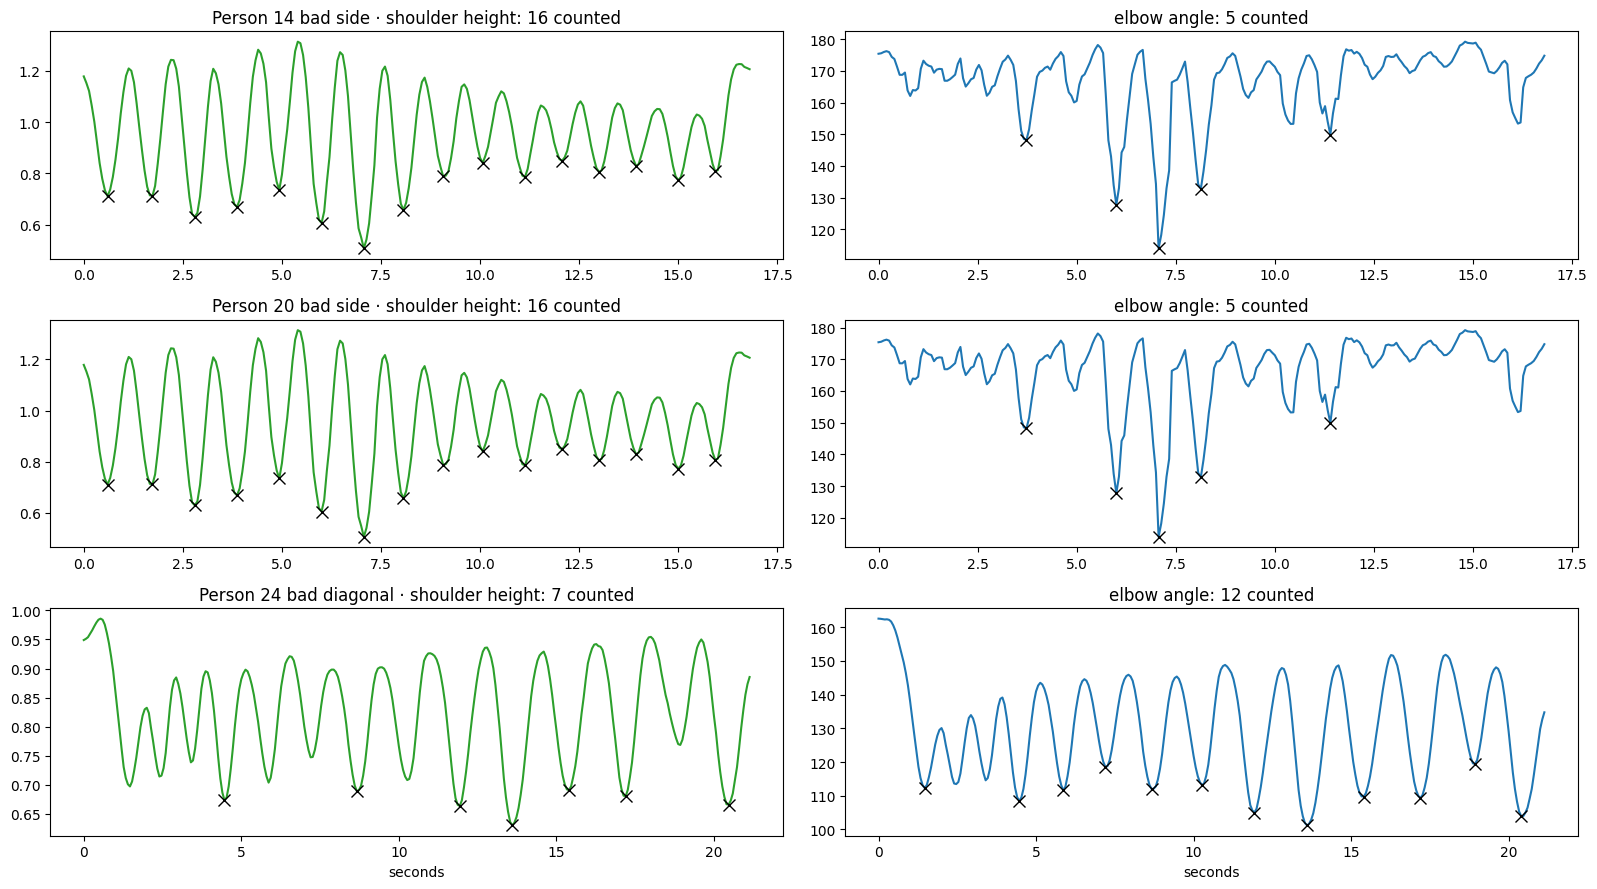

In [11]:
problem_videos = [(14, 'bad', 'side'), (20, 'bad', 'side'), (24, 'bad', 'diagonal')]
fig, axes = plt.subplots(len(problem_videos), 2, figsize=(16, 9))
for row_axes, (subject, quality, view) in zip(axes, problem_videos):
    landmarks = load_video(subject, 'push_up', quality, view)
    fps = landmarks['fps'].iloc[0]
    seconds = np.arange(len(landmarks)) / fps
    height_signal, angle_signal = pushup_signals(landmarks)
    gap = int(fps * 0.5)
    height_dips, _ = find_peaks(-height_signal, prominence=0.2, distance=gap)
    angle_dips, _ = find_peaks(180 - angle_signal, prominence=25, distance=gap)
    # The same signals and settings as the counter, so the ✕ marks match its counts.

    row_axes[0].plot(seconds, height_signal, color='tab:green')
    row_axes[0].plot(seconds[height_dips], height_signal[height_dips], 'x', color='black', markersize=9)
    row_axes[0].set_title(f'Person {subject} {quality} {view} · shoulder height: {len(height_dips)} counted')
    row_axes[1].plot(seconds, angle_signal, color='tab:blue')
    row_axes[1].plot(seconds[angle_dips], angle_signal[angle_dips], 'x', color='black', markersize=9)
    row_axes[1].set_title(f'elbow angle: {len(angle_dips)} counted')
    # Left: shoulder height with an ✕ on each counted dip. Right: elbow angle with an ✕ on each counted dip.
for axis in axes[-1]:
    axis.set_xlabel('seconds')
plt.tight_layout()
plt.show()

### 3.13 – Push-up counter v2: lower the shoulder-height threshold
**Why:** Person 24's shallow push-ups (~0.2 arm-length dips) were half-missed by the 0.2 threshold. Shoulder height is the more reliable signal overall (it caught 16 reps where the elbows barely bent).

**Change:** min_drop_height 0.2 → 0.1 (the noise in the charts is well below 0.1).

**Data issue found:** Persons 14 and 20 (bad, side) are the SAME video, a duplicate in the dataset.

**If something breaks:** If agreement gets WORSE, 0.1 is counting noise, so try 0.15.

In [12]:
pushup_results = []
for name, path in landmark_paths.items():
    if '_push_up_' not in name:
        continue
    parts = name.split('_')
    height_count, angle_count, _ = count_pushups(pd.read_parquet(path), min_drop_height=0.1)
    pushup_results.append({'subject': int(parts[1]), 'quality': parts[-2], 'view': parts[-1],
                           'by_height': height_count, 'by_elbow': angle_count})
pushup_results = pd.DataFrame(pushup_results)
pushup_results['difference'] = (pushup_results['by_height'] - pushup_results['by_elbow']).abs()

print('Signals agree (by view):        before → now')
before = {'diagonal': '90%', 'front': '98%', 'side': '77%'}
for view, group in pushup_results.groupby('view'):
    print(f'   {view:<9} within 1:  {before[view]} → {(group["difference"] <= 1).mean():.0%}')
print(f'\nOverall within 1: 88% → {(pushup_results["difference"] <= 1).mean():.0%}')
print('\nBiggest disagreements now:')
print(pushup_results.sort_values('difference', ascending=False).head(6).to_string(index=False))


Signals agree (by view):        before → now
   diagonal  within 1:  90% → 92%
   front     within 1:  98% → 98%
   side      within 1:  77% → 79%

Overall within 1: 88% → 90%

Biggest disagreements now:
 subject quality view  by_height  by_elbow  difference
      16     bad side         18         0          18
      14     bad side         16         5          11
      20     bad side         16         5          11
       3     bad side         14         6           8
      21     bad side         15         8           7
       1     bad side         18        14           4


### 3.14 – Push-up depth grading from the FRONT (elbow angle at the bottom)
**Why:** From the front, both elbows are clearly visible (98% signal agreement), so the elbow angle can grade depth like the curls.

**What:** For every push-up in the 48 front videos: find its bottom (shoulder-height dip), take the smallest elbow angle around it, and compare GOOD vs BAD videos.

**Goal:** Find an elbow-angle cutoff that separates good from bad, then check the % of "shallow" reps in good vs bad videos.

**Limitation:** Hip sag can't be seen from the front, so that's a future feature (side view).

581 push-ups from front videos
         count   25%   50%   75%
quality                         
bad      247.0  56.0  71.0  92.0
good     334.0  49.0  60.0  76.0
cutoff 80° → shallow reps: good 19% | bad 45%
cutoff 90° → shallow reps: good 12% | bad 28%
cutoff 100° → shallow reps: good 9% | bad 17%
cutoff 110° → shallow reps: good 7% | bad 11%


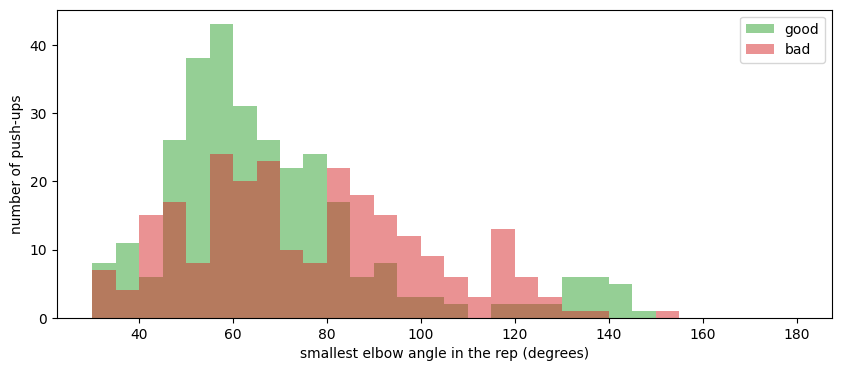

In [13]:
bottom_angles = []
for subject in range(1, 27):
    for quality in ['good', 'bad']:
        landmarks = load_video(subject, 'push_up', quality, 'front')
        if landmarks is None:
            continue
        fps = landmarks['fps'].iloc[0]
        height_signal, angle_signal = pushup_signals(landmarks)
        dips, _ = find_peaks(-height_signal, prominence=0.1, distance=max(int(fps * 0.5), 1))
        window = int(fps * 0.3)
        for dip in dips:
            nearby = angle_signal[max(dip - window, 0): dip + window + 1]
            bottom_angles.append({'subject': subject, 'quality': quality, 'bottom_elbow_angle': float(np.min(nearby))})
bottom_angles = pd.DataFrame(bottom_angles)

print(f'{len(bottom_angles)} push-ups from front videos')
print(bottom_angles.groupby('quality')['bottom_elbow_angle'].describe()[['count', '25%', '50%', '75%']].round(0))

for cutoff in [80, 90, 100, 110]:
    shallow_share = bottom_angles.assign(shallow=bottom_angles['bottom_elbow_angle'] > cutoff) \
                                 .groupby('quality')['shallow'].mean()
    print(f'cutoff {cutoff}° → shallow reps: good {shallow_share["good"]:.0%} | bad {shallow_share["bad"]:.0%}')

plt.figure(figsize=(10, 4))
for quality, color in [('good', 'tab:green'), ('bad', 'tab:red')]:
    plt.hist(bottom_angles.loc[bottom_angles['quality'] == quality, 'bottom_elbow_angle'],
             bins=30, range=(30, 180), alpha=0.5, color=color, label=quality)
plt.xlabel('smallest elbow angle in the rep (degrees)')
plt.ylabel('number of push-ups')
plt.legend()
plt.show()


### 3.15 – Get the push-up videos + pick examples to check by eye
**Why:** I want to SEE whether the depth grading ("good" vs "too shallow") matches what I see.

**What:** Downloads the Mendeley zip (if missing) and unpacks the FRONT push-up + curl videos. Lists which videos have the most "too shallow" reps, plus the "good" videos with odd 130°+ reps.

**If something breaks:** Internet must be ON. The download takes ~2–5 min (7.6 GB).

In [14]:
ZIP_PATH = '/kaggle/temp/mendeley.zip'
VIDEO_DIR = '/kaggle/temp/videos'
os.makedirs('/kaggle/temp', exist_ok=True)
if not os.path.exists(ZIP_PATH):
    !wget -q -O {ZIP_PATH} "https://data.mendeley.com/public-api/zip/kgbb3yn47p/download/2"
with zipfile.ZipFile(ZIP_PATH) as archive:
    front_files = [name for name in archive.namelist()
                   if 'Exercise Quality-wise/' in name and name.endswith('_front.mp4')
                   and ('/push_up/' in name or '/bicep_curl/' in name)]
    for name in front_files:
        archive.extract(name, VIDEO_DIR)
print(f'{len(front_files)} front videos unpacked (push-up + curl)')

def find_video_file(subject, exercise, quality, view='front'):
    matches = glob.glob(f'{VIDEO_DIR}/**/subject_{subject:03d}_{exercise}_{quality}_{view}.mp4', recursive=True)
    return matches[0] if matches else None

summary = bottom_angles.assign(shallow=bottom_angles['bottom_elbow_angle'] > 90) \
                       .groupby(['subject', 'quality']) \
                       .agg(reps=('shallow', 'size'), shallow_reps=('shallow', 'sum'),
                            deepest=('bottom_elbow_angle', 'min'), shallowest=('bottom_elbow_angle', 'max'))

print('\n🔴 BAD videos with the most "too shallow" reps:')
print(summary.xs('bad', level='quality').sort_values('shallow_reps', ascending=False).head(4).to_string())
print('\n🟢 GOOD videos with "too shallow" reps (possible false alarms or mislabels):')
print(summary.xs('good', level='quality').query('shallow_reps > 0').sort_values('shallow_reps', ascending=False).head(4).to_string())


98 front videos unpacked (push-up + curl)

🔴 BAD videos with the most "too shallow" reps:
         reps  shallow_reps    deepest  shallowest
subject                                           
16         18            18  108.56400  134.502446
22         13            13   92.81958  103.366668
4           8             8   92.90863  153.848902
14         11             8   74.85390  108.974451

🟢 GOOD videos with "too shallow" reps (possible false alarms or mislabels):
         reps  shallow_reps     deepest  shallowest
subject                                            
22         18            18  104.562553  143.380393
14         17            11   79.360353  106.005253
4           7             6   85.070466  147.314090
2          12             2   45.890444  140.939229


### 3.16 – Annotated push-up player (see the grading on the video)
**What:** `annotate_pushups(subject, quality)` plays the FRONT push-up video with the arm skeleton, the live elbow angle, the rep counter and each rep's grade (GOOD DEPTH / TOO SHALLOW) drawn on top.

**Check:** Does each "too shallow" call LOOK shallow to me? Start with person 22 (all reps flagged, even in the good video).

**Light:** 480 px wide, first 20 s, no sound, so the tab doesn't crash.

In [23]:
import subprocess
import cv2
from IPython.display import Video

GREEN, ORANGE, WHITE = (0, 200, 0), (0, 140, 255), (255, 255, 255)

def annotate_pushups(subject, quality, seconds=20, depth_cutoff=90):
    video_path = find_video_file(subject, 'push_up', quality)
    landmarks = load_video(subject, 'push_up', quality, 'front')
    fps = landmarks['fps'].iloc[0]
    height_signal, angle_signal = pushup_signals(landmarks)
    dips, _ = find_peaks(-height_signal, prominence=0.1, distance=max(int(fps * 0.5), 1))
    window = int(fps * 0.3)
    bottom_angles_here = [float(np.min(angle_signal[max(d - window, 0): d + window + 1])) for d in dips]

    capture = cv2.VideoCapture(video_path)
    output = cv2.VideoWriter('annotated_raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps,
                             (480, int(480 * landmarks['height'].iloc[0] / landmarks['width'].iloc[0])))
    frame_index, reps_done, last_grade = 0, 0, None
    while frame_index < seconds * fps:
        ok, frame = capture.read()
        if not ok:
            break
        frame = cv2.resize(frame, (480, int(480 * frame.shape[0] / frame.shape[1])))
        frame_height, frame_width = frame.shape[:2]
        # Reads each frame and shrinks it to 480 px wide (light + fast).

        point = lambda number: (int(landmarks.loc[frame_index, f'{number}_x'] * frame_width),
                                int(landmarks.loc[frame_index, f'{number}_y'] * frame_height))
        if not np.isnan(landmarks.loc[frame_index, '13_x']):
            for shoulder, elbow, wrist in [(11, 13, 15), (12, 14, 16)]:
                cv2.line(frame, point(shoulder), point(elbow), WHITE, 2)
                cv2.line(frame, point(elbow), point(wrist), WHITE, 2)
                cv2.circle(frame, point(elbow), 5, ORANGE, -1)
        # Draws both arms (shoulder → elbow → wrist) using the saved body points for THIS frame.

        while reps_done < len(dips) and dips[reps_done] <= frame_index:
            angle_at_bottom = bottom_angles_here[reps_done]
            last_grade = ('GOOD DEPTH', GREEN) if angle_at_bottom <= depth_cutoff else ('TOO SHALLOW', ORANGE)
            last_grade = (f'{last_grade[0]} ({angle_at_bottom:.0f} deg)', last_grade[1])
            reps_done += 1
        # When the video reaches a rep's bottom frame: count it and grade it (≤ 90° = good depth).

        cv2.putText(frame, f'Rep {reps_done} / {len(dips)}', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, WHITE, 2)
        cv2.putText(frame, f'elbow: {angle_signal[frame_index]:.0f} deg', (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, WHITE, 2)
        if last_grade:
            cv2.putText(frame, f'last rep: {last_grade[0]}', (10, 90), cv2.FONT_HERSHEY_SIMPLEX, 0.7, last_grade[1], 2)
        output.write(frame)
        frame_index += 1

    capture.release()
    output.release()
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', 'annotated_raw.mp4', '-an', '-vcodec', 'libx264',
                    '-crf', '30', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', 'annotated.mp4'])
    print(f'Person {subject} · push-up · {quality} · front | {len(dips)} reps | '
          f'{sum(a > depth_cutoff for a in bottom_angles_here)} graded too shallow')
    return Video('annotated.mp4', embed=True, width=480)

annotate_pushups(4, 'bad', seconds=40)
# Then try: annotate_pushups(22, 'bad'), annotate_pushups(4, 'good'), annotate_pushups(1, 'good') ...


Person 4 · push-up · bad · front | 8 reps | 8 graded too shallow
